# 02 · Data visualisation, query optimisation results and peak timing

This notebook produces the descriptive part of the paper:

| Output | Paper | Input |
|---|---|---|
| Monthly GT vs MC series, 2015–2025 | Figure 1 | `data/processed/monthly/` (from notebook 01) |
| Snowball stability of the GT query | Figure 9 | `data/processed/queries/` (from notebook 01) |
| Top k-grams of MediaCloud articles | Figure 10 | `data/processed/queries/` (from notebook 01) |
| Daily seasons aligned on the GT peak | Figures 2–3 | `data/processed/daily/` (included) |
| Lag between MC and GT peaks | Table 1 | `data/processed/daily/` (included) |

The daily data used in the paper are included in the repository, so Figures 2–3 and
Table 1 run immediately. Figures 1, 9 and 10 need the outputs of notebook 01; their
cells are skipped with a message if those files are missing.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "phc").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from phc.config import CAMPAIGNS, ORDER, FIG_DIR, TAB_DIR, MONTHLY_DIR, QUERY_DIR, gt_query
from phc.granger import load_daily

GT_COLOR, MC_COLOR = "#2a6fb0", "#e08a2c"
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

## 1. Queries used

Search language and editorial language differ, so the two channels use different
queries. Google Trends terms are combined with `+` (logical OR in Google Trends);
MediaCloud terms are combined with `OR`.

In [2]:
pd.DataFrame({
    "Google Trends query": {CAMPAIGNS[c].label: gt_query(CAMPAIGNS[c]) for c in ORDER},
    "MediaCloud query": {CAMPAIGNS[c].label: " OR ".join(CAMPAIGNS[c].mc_terms) for c in ORDER},
})

,Google Trends query,MediaCloud query
Octobre Rose,Octobre rose + cancer du sein + mammographie + dépistage cancer du sein + cancer du sein symptôme,octobre rose OR cancer sein OR lutte contre cancer sein OR dépistage cancer sein OR mois octobre rose
Movember,Movember + cancer prostate + movember prostate + cancer prostate psa + cancer prostate traitement,movember OR cancer prostate OR mois movember OR masculin cancer prostate OR maladie masculin cancer prostate
Mars Bleu,Mars bleu + cancer colorectal + dépistage colon + coloscopie + cancer colon,mars bleu OR cancer colorectal OR dépistage cancer colorectal OR cancer colorectal cancer OR mois mars bleu
Dry January,dry january + mois sans alcool + arreter de boire + janvier sans alcool + arreter alcool,dry january OR consommation alcool OR mois alcool OR boire alcool mois OR dry january janvier OR alcool mois janvier


## 2. Monthly series, 2015–2025 (Figure 1)

Each series is divided by its own maximum over 2015–2025 and multiplied by 100.

In [3]:
gt_m_path, mc_m_path = MONTHLY_DIR / "GT_monthly.csv", MONTHLY_DIR / "MC_monthly.csv"

if gt_m_path.exists() and mc_m_path.exists():
    gt_m = pd.read_csv(gt_m_path, parse_dates=["date"])
    mc_m = pd.read_csv(mc_m_path, parse_dates=["date"])
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    for ax, c in zip(axes.flat, ORDER):
        g = gt_m[gt_m["code"] == c].set_index("date")["value"]
        m = mc_m[mc_m["code"] == c].set_index("date")["value"]
        ax.plot(g.index, 100 * g / g.max(), color=GT_COLOR, lw=1.6, label="Google Trends")
        ax.plot(m.index, 100 * m / m.max(), color=MC_COLOR, lw=1.3, ls="--", label="MediaCloud")
        ax.set(title=CAMPAIGNS[c].label, ylabel="Normalised (max = 100)", ylim=(0, 105))
        ax.xaxis.set_major_locator(mdates.YearLocator(2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[0, 0].legend()
    fig.suptitle("Monthly Google Trends and MediaCloud series, 2015–2025")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig01_monthly_gt_mc.png", dpi=200, bbox_inches="tight")
else:
    print("Monthly series not found. Run section 4 of notebook 01 to create",
          gt_m_path.relative_to(ROOT), "and", mc_m_path.relative_to(ROOT))

Monthly series not found. Run section 4 of notebook 01 to create data/processed/monthly/GT_monthly.csv and data/processed/monthly/MC_monthly.csv


## 3. Query optimisation results (Figures 9 and 10)

**Figure 9** checks that the Google Trends signal is stable when the snowball adds
terms: if the curve keeps its shape across rounds, extra terms add volume but no new
dynamics. **Figure 10** shows the most frequent bigrams and trigrams in the MediaCloud
articles of the first collection, from which the MC query terms were selected by hand.

In [4]:
snow_path = QUERY_DIR / "gt_snowball_rounds_MB.csv"
if snow_path.exists():
    snow = pd.read_csv(snow_path, parse_dates=["date"])
    fig, ax = plt.subplots(figsize=(12, 4))
    for r, d in snow.groupby("round"):
        ax.plot(d["date"], d["value"], lw=1.3, label=f"Round {r}")
    ax.set(title="Google Trends signal for Mars Bleu across snowball rounds",
           ylabel="Interest (0–100)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig09_snowball_mars_bleu.png", dpi=200, bbox_inches="tight")
    # Quantify stability: correlation of each round with the last one
    wide = snow.pivot(index="date", columns="round", values="value")
    print("Correlation with the last round:\n", wide.corr()[wide.columns[-1]].round(3))
else:
    print("Snowball rounds not found. Run section 2 of notebook 01 to create", snow_path.relative_to(ROOT))

Snowball rounds not found. Run section 2 of notebook 01 to create data/processed/queries/gt_snowball_rounds_MB.csv


In [5]:
kg_path = QUERY_DIR / "mc_kgrams_DJ.csv"
if kg_path.exists():
    kg = pd.read_csv(kg_path)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, n, title in zip(axes, (2, 3), ("Bigrams", "Trigrams")):
        top = kg[kg["n"] == n].nlargest(15, "count").iloc[::-1]
        ax.barh(top["kgram"], top["count"], color=GT_COLOR)
        ax.set(title=title, xlabel="Occurrences")
        ax.grid(axis="y", alpha=0)
    fig.suptitle("Top 15 k-grams in MediaCloud articles — Dry January")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig10_kgrams_dry_january.png", dpi=200, bbox_inches="tight")
else:
    print("k-gram counts not found. Run section 3 of notebook 01 to create", kg_path.relative_to(ROOT))

k-gram counts not found. Run section 3 of notebook 01 to create data/processed/queries/mc_kgrams_DJ.csv


## 4. Daily seasonal windows

Daily data are restricted to a window around each yearly campaign. GT is retrieved
separately for each window (so 100 is the maximum of that season) and MC article counts
are divided by their seasonal maximum, so both series are on a 0–100 scale within each
season.

In [6]:
data = {c: load_daily(c) for c in ORDER}
windows = pd.DataFrame({
    CAMPAIGNS[c].label: {
        "window": f"{CAMPAIGNS[c].window_start[1]:02d}/{CAMPAIGNS[c].window_start[0]:02d}"
                  f" → {CAMPAIGNS[c].window_end[1]:02d}/{CAMPAIGNS[c].window_end[0]:02d}",
        "days per season": int(data[c].groupby("season").size().median()),
        "seasons": data[c]["season"].nunique(),
    } for c in ORDER}).T
windows

,window,days per season,seasons
Octobre Rose,01/09 → 30/11,91,11
Movember,01/10 → 31/12,92,11
Mars Bleu,02/02 → 30/04,88,11
Dry January,26/12 → 06/02,43,11


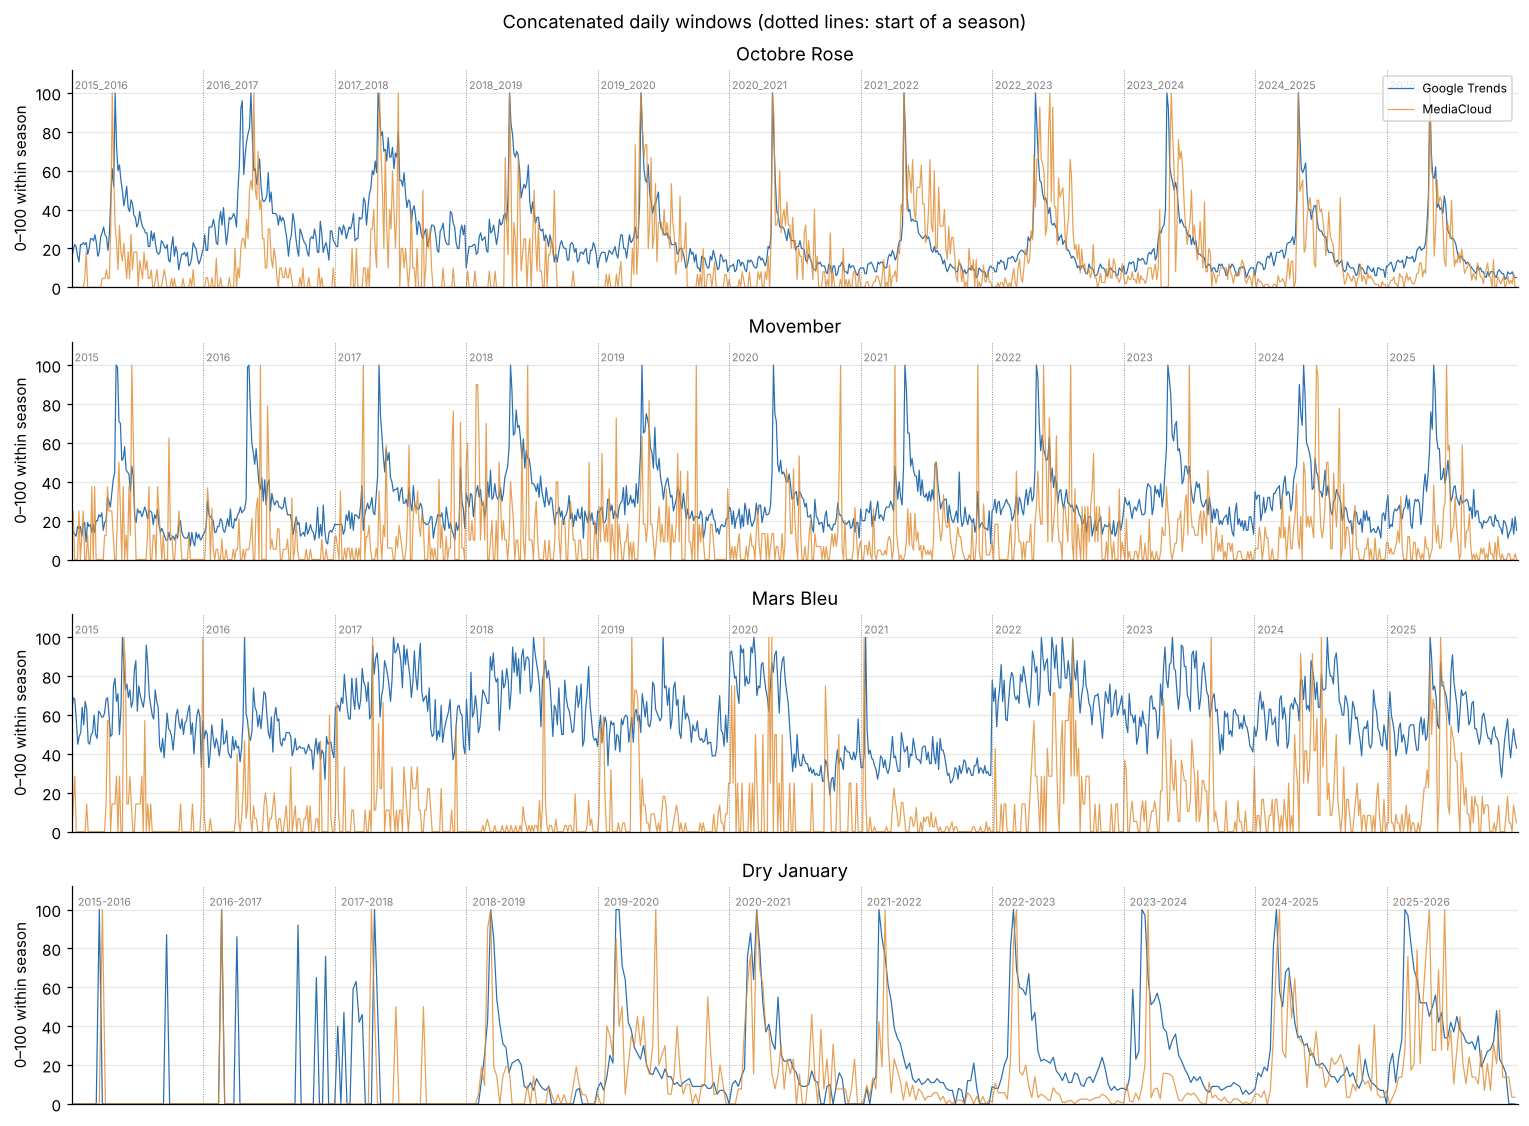

In [7]:
fig, axes = plt.subplots(len(ORDER), 1, figsize=(14, 2.6 * len(ORDER)))
for ax, c in zip(axes, ORDER):
    d = data[c].reset_index(drop=True)
    ax.plot(d.index, d["gt"], color=GT_COLOR, lw=0.8, label="Google Trends")
    ax.plot(d.index, d["mc"], color=MC_COLOR, lw=0.8, alpha=0.8, label="MediaCloud")
    starts = d.groupby("season", sort=False).head(1)
    for i, s in zip(starts.index, starts["season"]):
        ax.axvline(i, color="grey", lw=0.6, ls=":")
        ax.text(i + 2, 102, s, fontsize=7, color="grey")
    ax.set(title=CAMPAIGNS[c].label, ylabel="0–100 within season", ylim=(0, 112),
           xlim=(0, len(d)))
    ax.set_xticks([])
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Concatenated daily windows (dotted lines: start of a season)")
fig.tight_layout()
fig.savefig(FIG_DIR / "daily_windows_overview.png", dpi=200, bbox_inches="tight")

## 5. Seasons aligned on the GT peak (Figures 2–3)

For each season, day 0 is the day of maximum GT interest. The panel title gives the
lag between the MC peak and the GT peak (positive: media peak after search peak).
Both series are rescaled to [0, 1] within the season for display.

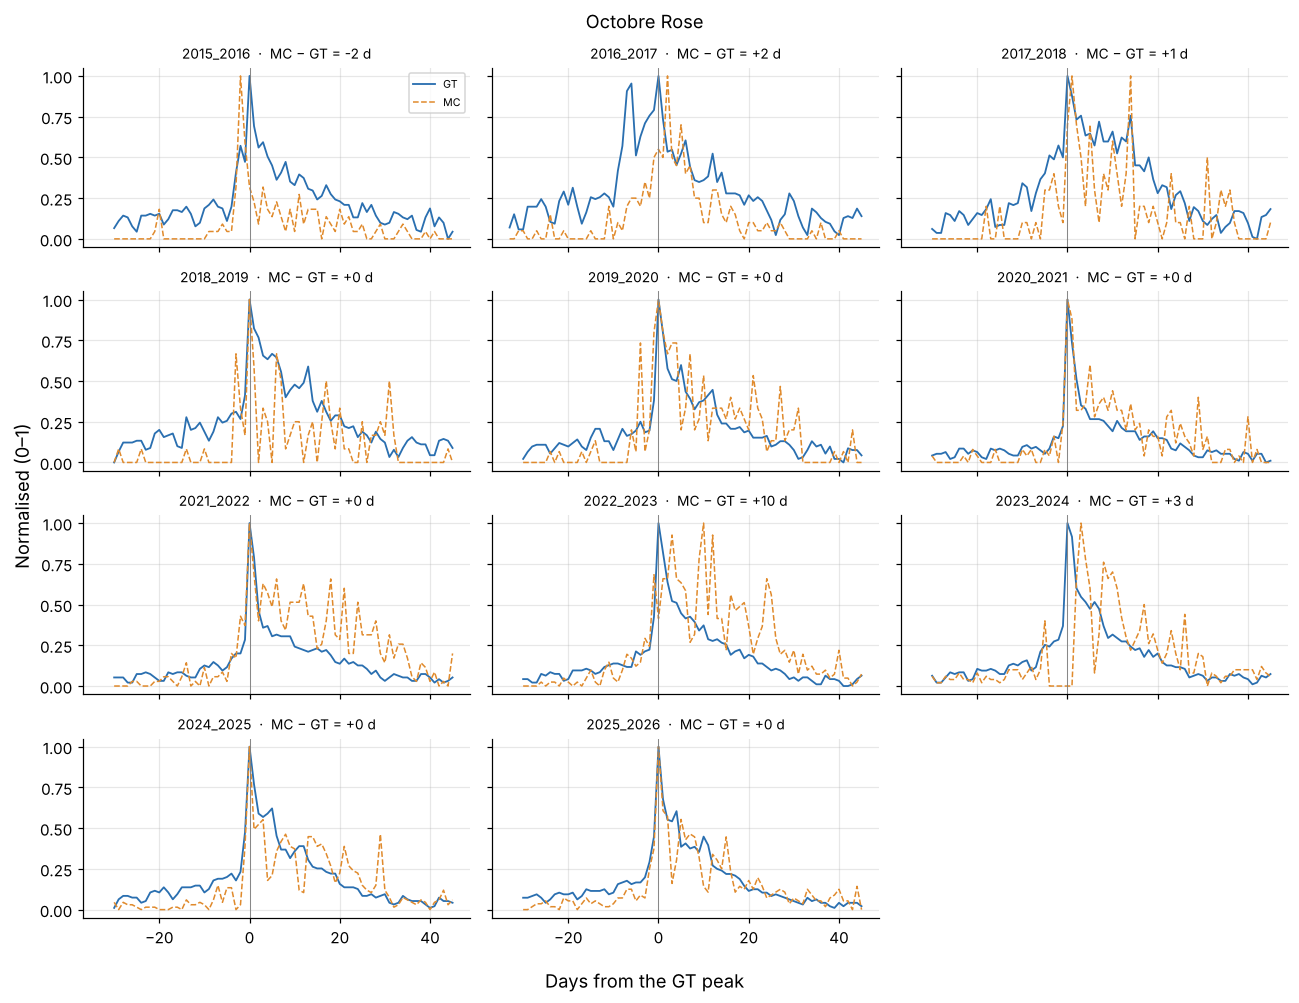

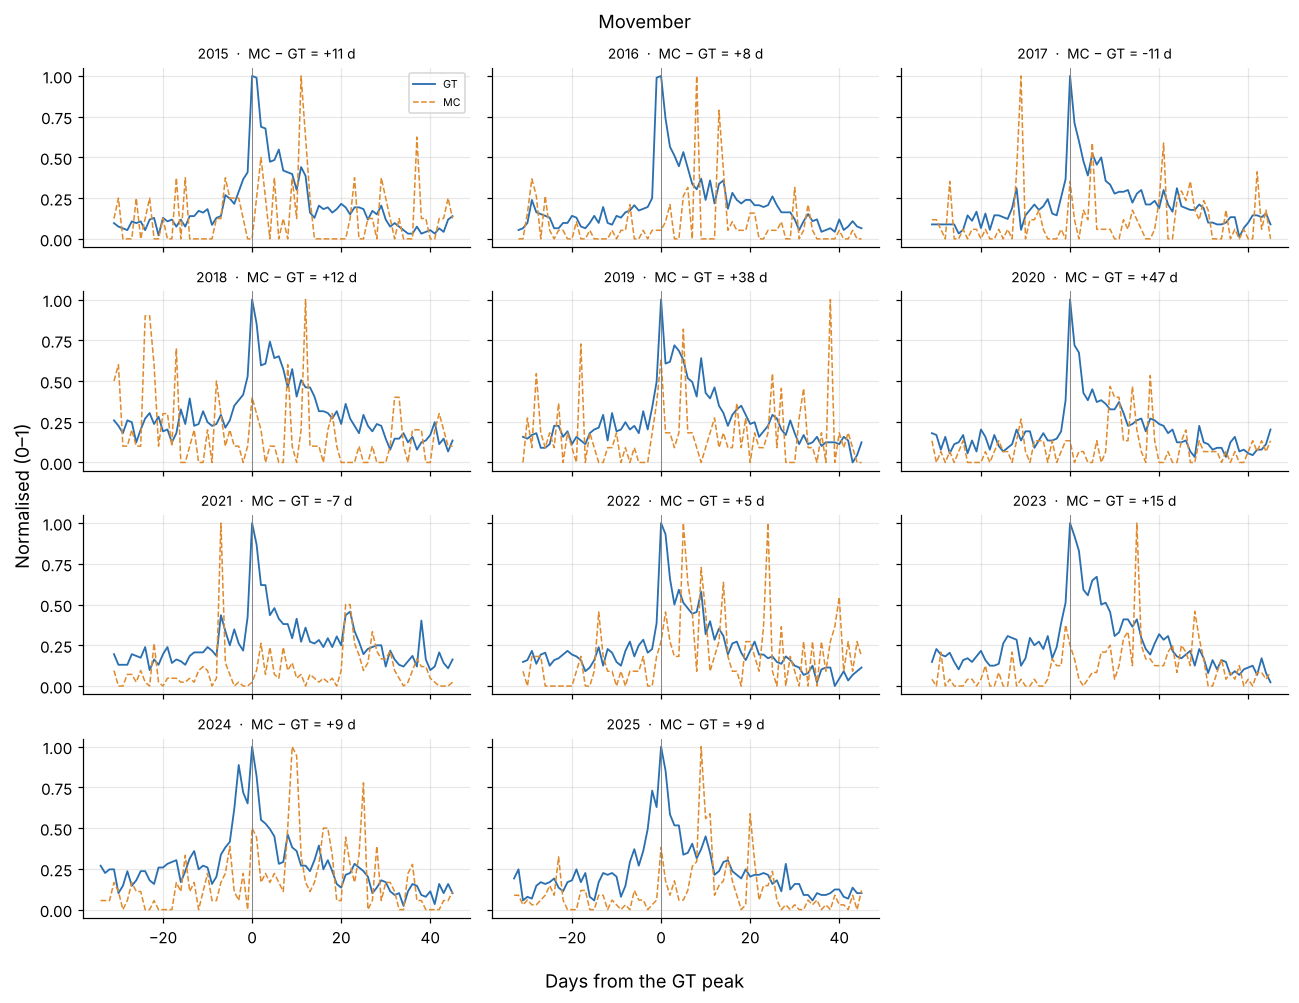

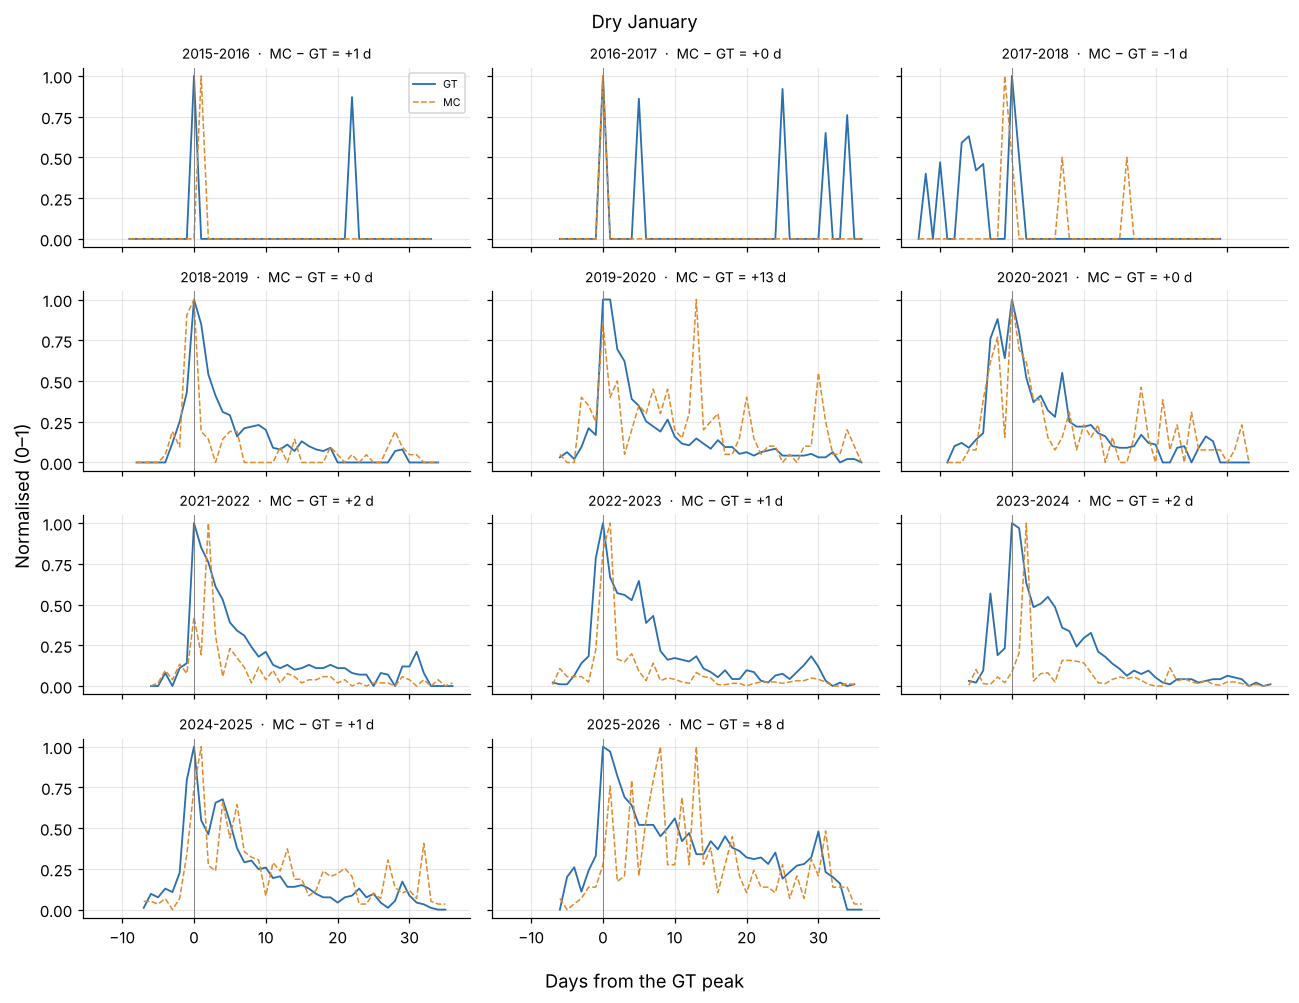

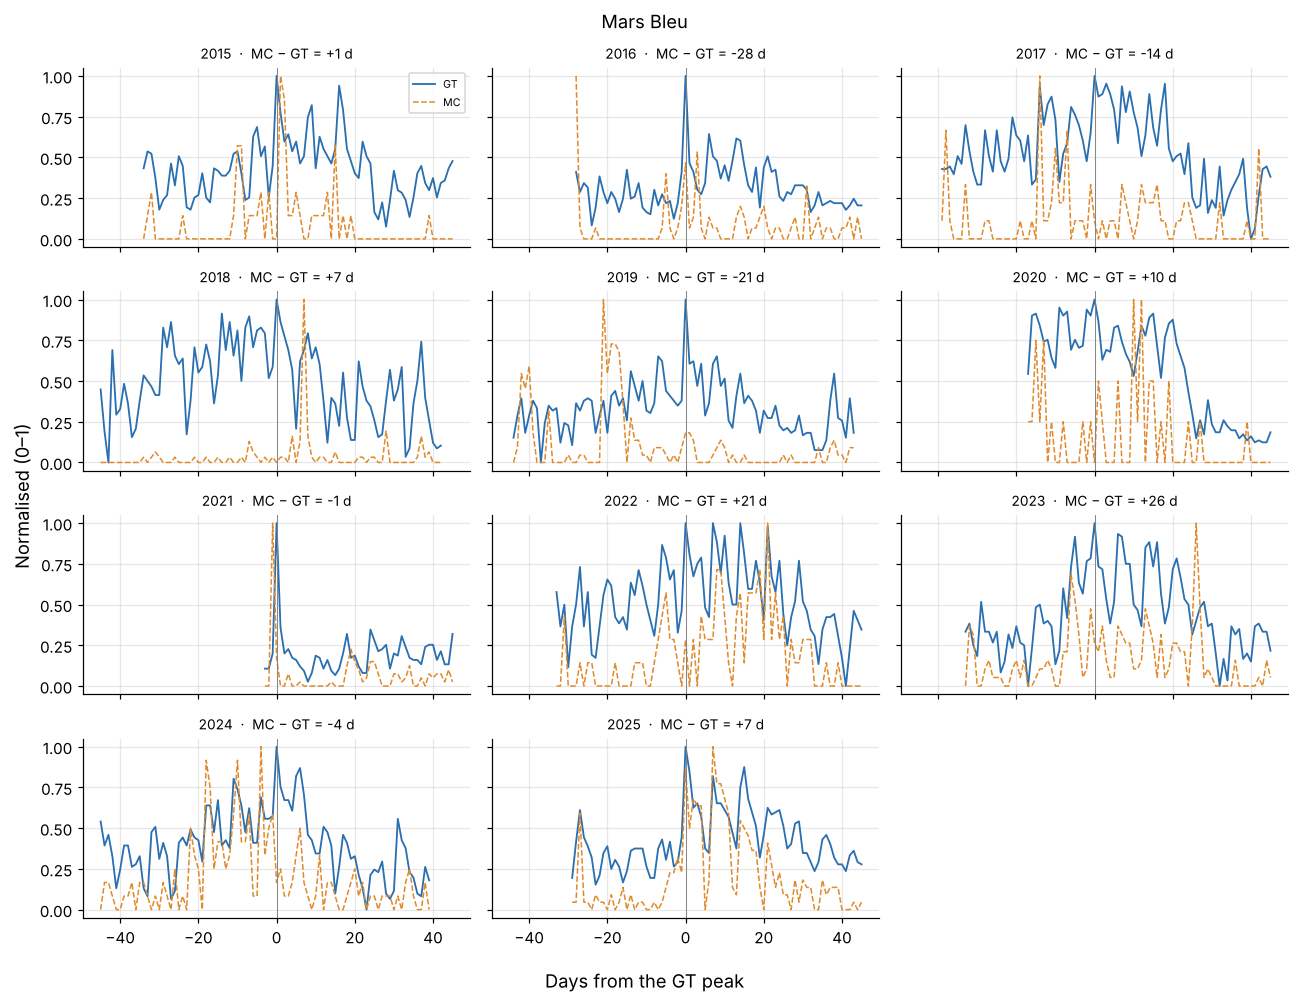

In [8]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0


def aligned(df):
    out = []
    for season, g in df.reset_index().groupby("season", sort=False):
        gt_peak = g.loc[g["gt"].idxmax(), "date"]    # first day of the maximum
        mc_peak = g.loc[g["mc"].idxmax(), "date"]
        out.append(g.assign(day=(g["date"] - gt_peak).dt.days,
                            gt01=minmax(g["gt"]), mc01=minmax(g["mc"]),
                            lag=(mc_peak - gt_peak).days))
    return pd.concat(out, ignore_index=True)


def plot_aligned(c, fname, window=45):
    a = aligned(data[c])
    seasons = a["season"].unique()
    ncol = 3
    nrow = int(np.ceil(len(seasons) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(12, 2.3 * nrow), sharex=True, sharey=True)
    for ax, s in zip(axes.flat, seasons):
        g = a[(a["season"] == s) & a["day"].between(-window, window)]
        ax.plot(g["day"], g["gt01"], color=GT_COLOR, lw=1.2, label="GT")
        ax.plot(g["day"], g["mc01"], color=MC_COLOR, lw=1.0, ls="--", label="MC")
        ax.axvline(0, color="grey", lw=0.6)
        ax.set_title(f"{s}  ·  MC − GT = {g['lag'].iloc[0]:+d} d", fontsize=9)
    for ax in axes.flat[len(seasons):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=7)
    fig.supxlabel("Days from the GT peak")
    fig.supylabel("Normalised (0–1)")
    fig.suptitle(CAMPAIGNS[c].label)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=200, bbox_inches="tight")


plot_aligned("OR", "fig02a_peaks_octobre_rose.png")
plot_aligned("Mov", "fig02b_peaks_movember.png")
plot_aligned("DJ", "fig03a_peaks_dry_january.png")
plot_aligned("MB", "fig03b_peaks_mars_bleu.png")

## 6. Lag between media and search peaks (Table 1)

In [9]:
lags = pd.DataFrame([
    {"campaign": CAMPAIGNS[c].label, "season": s, "lag_days": g["lag"].iloc[0]}
    for c in ORDER for s, g in aligned(data[c]).groupby("season", sort=False)
])
lags.to_csv(TAB_DIR / "peak_lags_by_season.csv", index=False)

table1 = lags.groupby("campaign", sort=False)["lag_days"].agg(
    median="median", min="min", max="max",
    within_2_days=lambda x: f"{(x.abs() <= 2).sum()}/{len(x)}")
table1.to_csv(TAB_DIR / "table1_peak_lags.csv")
table1

,median,min,max,within_2_days
campaign,,,,
Octobre Rose,0.0,-2,10,9/11
Movember,9.0,-11,47,0/11
Mars Bleu,1.0,-28,26,2/11
Dry January,1.0,-1,13,9/11


In [10]:
# Lag by season (the season is labelled by the year in which the campaign window starts)
lags.assign(year=lags["season"].str[:4]).pivot(index="year", columns="campaign", values="lag_days")

campaign,Dry January,Mars Bleu,Movember,Octobre Rose
year,,,,
2015,1,1,11,-2
2016,0,-28,8,2
2017,-1,-14,-11,1
2018,0,7,12,0
2019,13,-21,38,0
2020,0,10,47,0
2021,2,-1,-7,0
2022,1,21,5,10
2023,2,26,15,3


Media and search peaks fall within two days of each other in 9 of 11 seasons for
Octobre Rose and Dry January. For Movember the media peak follows the search peak by a
median of 9 days and never falls within two days of it. Mars Bleu has no stable
alignment (lags from −28 to +26 days).

A peak is a single day, so this summary is sensitive to noise in daily data. The
Granger analysis in notebook 03 uses the whole daily dynamics instead.